# La poule qui chante — Étude de marché à l'international
## Notebook 2 — ACP, clustering (CAH + k-means) et visualisations

**Entrée** : `data/p11_countries_clean.csv` (notebook 1) — 166 pays, 13 variables PESTEL.

**Démarche**
1. Standardisation des variables
2. Analyse en composantes principales (ACP) : éboulis, cercles des corrélations, projection des individus
3. Classification ascendante hiérarchique (CAH, méthode de Ward) : dendrogramme, choix du nombre de groupes
4. k-means : choix de k, stabilité, comparaison avec la CAH
5. Profil des groupes et visualisations
6. Sélection des pays cibles et recommandations

## 1. Imports, chargement et standardisation

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

df = pd.read_csv(DATA_DIR / "p11_countries_clean.csv")
print(df.shape)
df.head(3)

(166, 25)


,iso3,zone,wb_region,income_group,capital,population,poultry_production_kt,poultry_imports_kt,poultry_exports_kt,poultry_domestic_supply_kt,poultry_food_market_kt,gdp_cap_ppp,distance_paris_km,poultry_supply_kg_cap,log_poultry_imports,import_dependency_pct,poultry_share_meat_pct,animal_protein_share_pct,log_population,pop_growth_10y_pct,log_gdp_cap_ppp,urban_pct,political_stability,regulatory_quality,lpi_score
0,ARM,Arménie,Europe & Central Asia,Upper middle income,Yerevan,2944791.0,11.0,35.0,0.0,47.0,47.293343,14243.874900,3431.470023,16.06,1.556303,76.086957,35.180723,45.782390,6.469054,0.415090,4.153628,64.712495,-0.301588,0.265850,2.61
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,36296113.0,28.0,29.0,0.0,57.0,55.533053,2952.998916,5581.827163,1.53,1.477121,50.877193,17.811409,19.523017,7.559860,33.931347,3.470263,24.835282,-2.613931,-1.416448,1.95
2,ALB,Albanie,Europe & Central Asia,Upper middle income,Tirane,2884169.0,13.0,38.0,0.0,47.0,47.185005,15359.397458,1600.454391,16.36,1.591065,74.509804,34.434856,55.497908,6.460021,-4.938335,4.186374,55.980276,0.163830,0.110524,2.66


In [2]:
FEATURES = [
    "poultry_supply_kg_cap", "log_poultry_imports", "import_dependency_pct", "poultry_share_meat_pct",
    "animal_protein_share_pct", "log_population", "pop_growth_10y_pct", "log_gdp_cap_ppp", "urban_pct",
    "political_stability", "regulatory_quality", "lpi_score", "distance_paris_km",
]
LABELS_FR = {
    "poultry_supply_kg_cap": "Volaille kg/hab", "log_poultry_imports": "Import. volaille (log)",
    "import_dependency_pct": "Dépendance import.", "poultry_share_meat_pct": "Part volaille/viande",
    "animal_protein_share_pct": "Protéines animales", "log_population": "Population (log)",
    "pop_growth_10y_pct": "Croiss. démo 10 ans", "log_gdp_cap_ppp": "PIB/hab PPA (log)",
    "urban_pct": "Urbanisation", "political_stability": "Stabilité politique",
    "regulatory_quality": "Qualité réglementaire", "lpi_score": "Logistique (LPI)",
    "distance_paris_km": "Distance Paris",
}
X_raw = df[FEATURES].to_numpy()
X = StandardScaler().fit_transform(X_raw)
names = df["zone"].to_numpy()
print(X.shape, "| means ≈ 0:", np.allclose(X.mean(0), 0), "| std ≈ 1:", np.allclose(X.std(0), 1))

(166, 13) | means ≈ 0: True | std ≈ 1: True


Les variables ont des unités très différentes (kg, %, km, indices). ACP et clustering reposent sur des distances euclidiennes : sans **centrage-réduction**, la distance (en km) écraserait tout. Chaque variable a donc désormais moyenne 0 et écart-type 1 (ACP *normée*).

## 2. Analyse en composantes principales

### 2.1 Éboulis des valeurs propres

In [3]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
eig = pd.DataFrame({
    "eigenvalue": pca.explained_variance_ * (len(X) - 1) / len(X),  # population-variance convention
    "variance_pct": pca.explained_variance_ratio_ * 100,
}, index=[f"F{i+1}" for i in range(len(FEATURES))])
eig["cumulative_pct"] = eig["variance_pct"].cumsum()
eig.round(2)

,eigenvalue,variance_pct,cumulative_pct
F1,5.23,40.21,40.21
F2,2.14,16.48,56.69
F3,1.34,10.34,67.03
F4,1.27,9.73,76.76
F5,0.86,6.62,83.38
F6,0.68,5.22,88.60
F7,0.48,3.71,92.31
F8,0.35,2.66,94.96
F9,0.19,1.44,96.40
F10,0.14,1.11,97.51


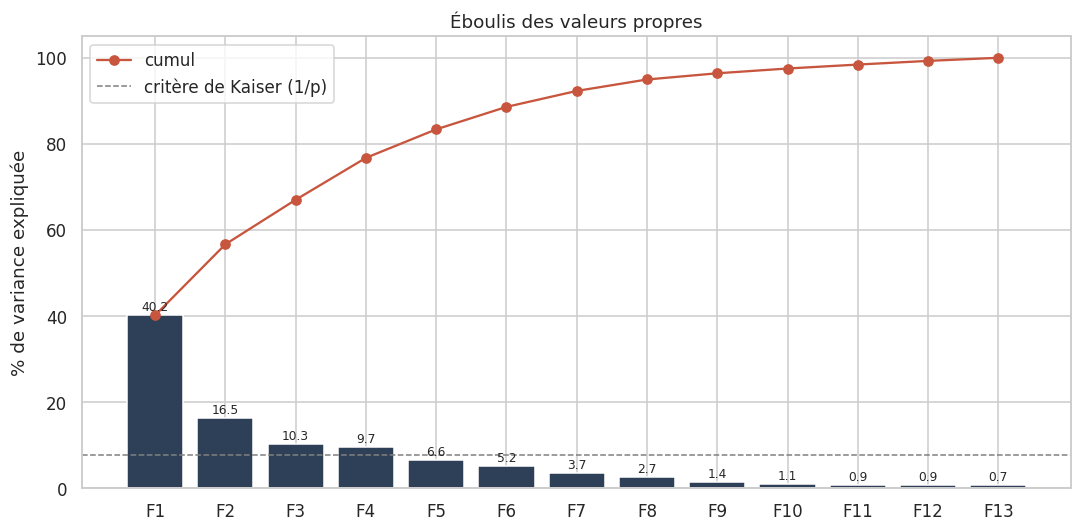

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(eig.index, eig["variance_pct"], color="#2E4057")
ax.plot(eig.index, eig["cumulative_pct"], "o-", c="#C8553D", label="cumul")
ax.axhline(100 / len(FEATURES), ls="--", c="grey", lw=1, label="critère de Kaiser (1/p)")
for i, (v, c) in enumerate(zip(eig["variance_pct"], eig["cumulative_pct"])):
    ax.text(i, v + 1, f"{v:.1f}", ha="center", fontsize=8)
ax.set_ylabel("% de variance expliquée")
ax.set_title("Éboulis des valeurs propres")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "pca_scree.png", dpi=200, bbox_inches="tight")
plt.show()

**Choix du nombre d'axes** : critère de Kaiser (valeur propre > 1) et coude → **4 composantes**, qui résument **≈ 77 %** de l'information des 13 variables. Le 5ᵉ axe (valeur propre < 1) apporte moins qu'une variable d'origine.

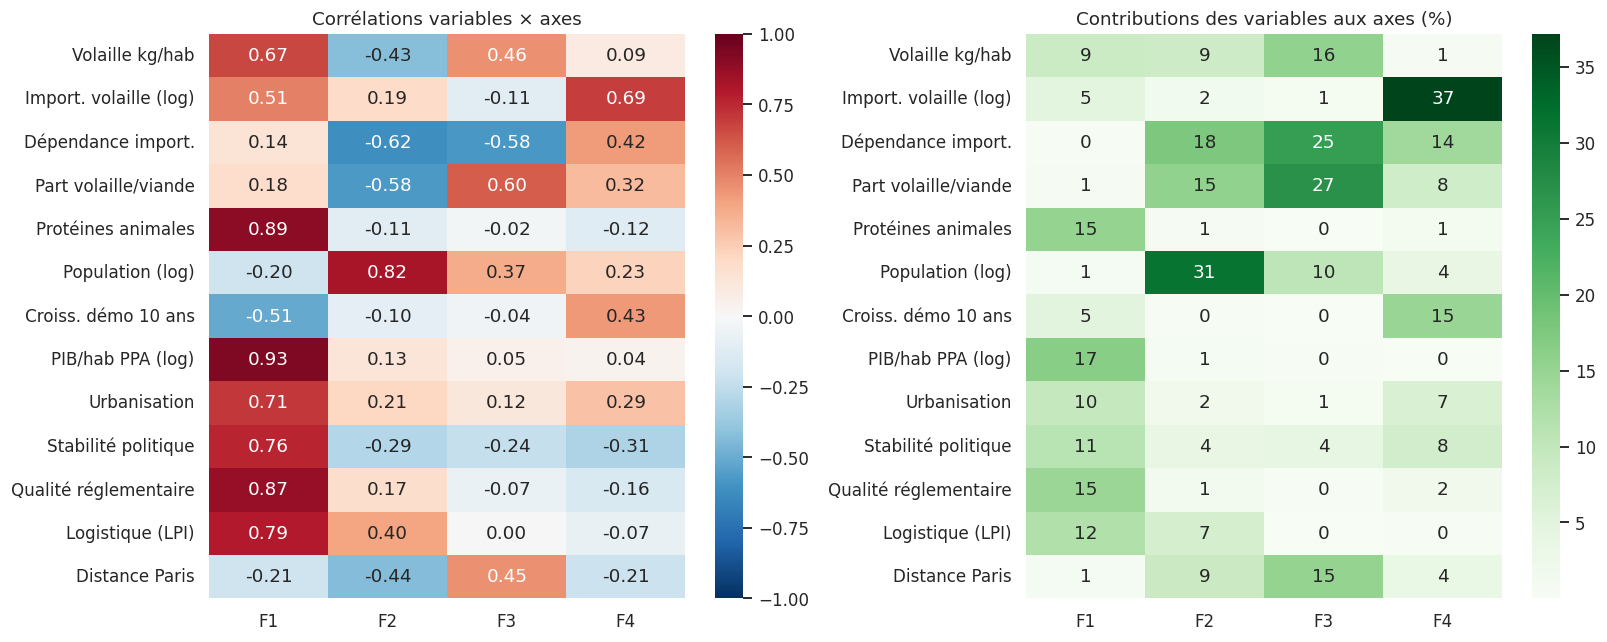

In [5]:
N_COMP = 4
pca = PCA(n_components=N_COMP, random_state=RANDOM_STATE).fit(X)
coords = pca.transform(X)
PC = [f"F{i+1}" for i in range(N_COMP)]
# correlations between variables and components (loadings scaled by sqrt(eigenvalue))
loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index=FEATURES, columns=PC)
contrib = pd.DataFrame(pca.components_.T ** 2 * 100, index=FEATURES, columns=PC)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(loadings.rename(index=LABELS_FR), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Corrélations variables × axes")
sns.heatmap(contrib.rename(index=LABELS_FR), annot=True, fmt=".0f", cmap="Greens", ax=axes[1])
axes[1].set_title("Contributions des variables aux axes (%)")
plt.tight_layout()
plt.show()

### 2.2 Cercles des corrélations

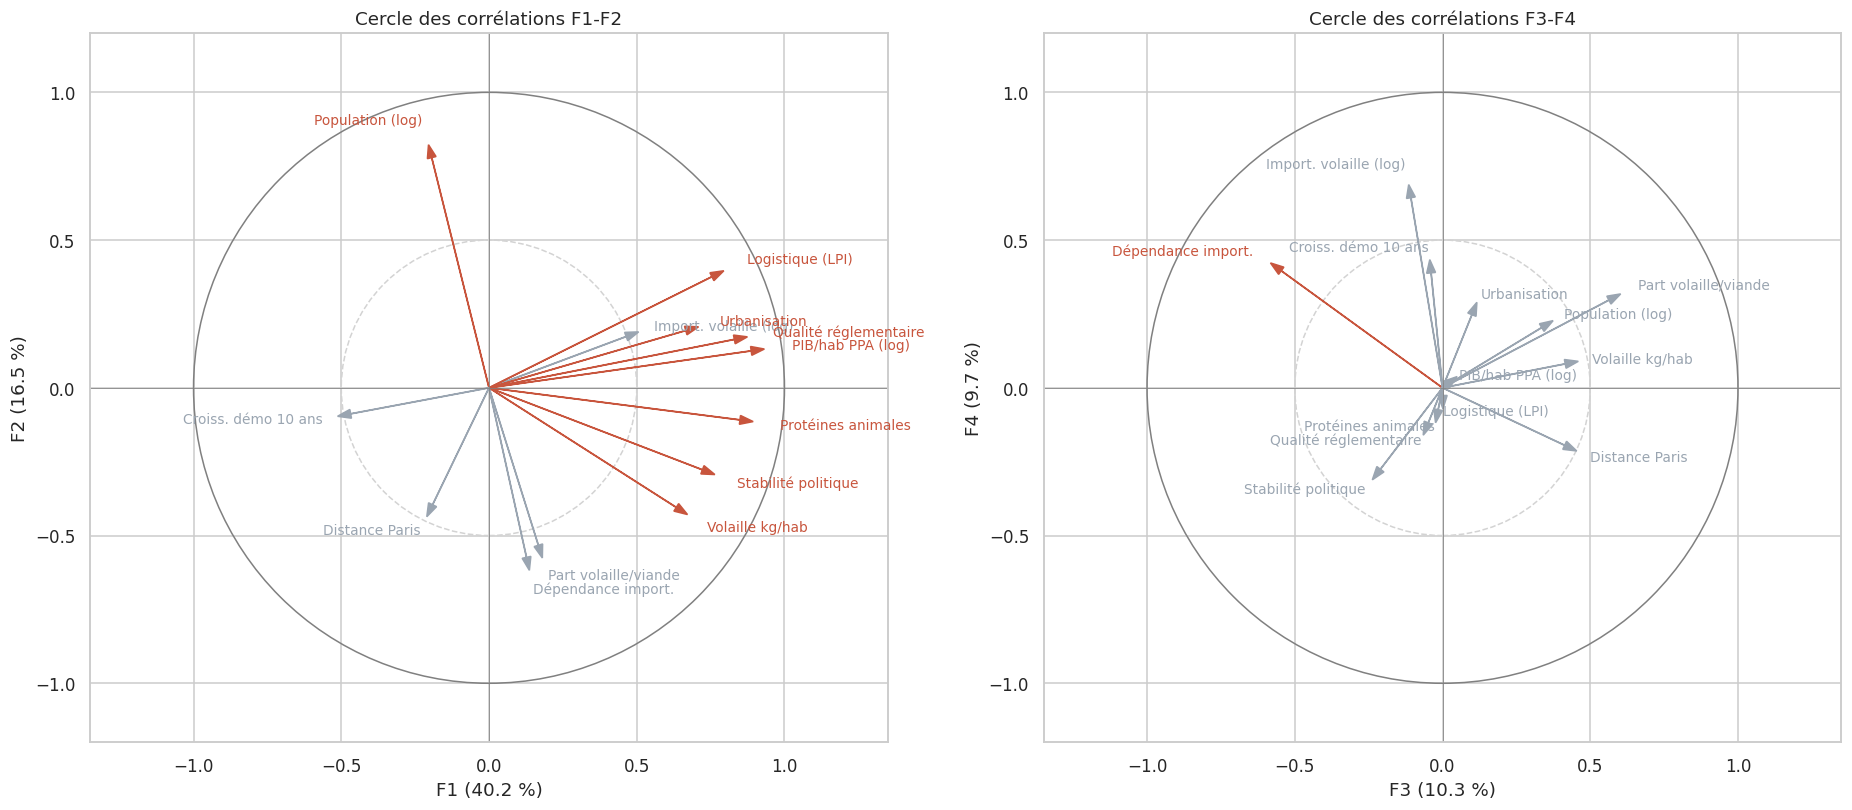

In [6]:
def correlation_circle(loadings, x, y, ax, var_pct):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
    ax.add_patch(plt.Circle((0, 0), .5, fill=False, color="lightgrey", ls="--"))
    for var, row in loadings.iterrows():
        quality = row[x] ** 2 + row[y] ** 2
        color = "#C8553D" if quality >= .5 else "#9AA5B1"
        ax.arrow(0, 0, row[x], row[y], head_width=.03, length_includes_head=True, color=color)
        ax.text(row[x] * 1.1, row[y] * 1.1, LABELS_FR[var], fontsize=9, color=color,
                ha="left" if row[x] >= 0 else "right", va="center")
    ax.axhline(0, c="grey", lw=.5)
    ax.axvline(0, c="grey", lw=.5)
    ax.set_xlim(-1.35, 1.35)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect("equal")
    ax.set_xlabel(f"{x} ({var_pct[x]:.1f} %)")
    ax.set_ylabel(f"{y} ({var_pct[y]:.1f} %)")
    ax.set_title(f"Cercle des corrélations {x}-{y}")

var_pct = eig["variance_pct"]
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
correlation_circle(loadings, "F1", "F2", axes[0], var_pct)
correlation_circle(loadings, "F3", "F4", axes[1], var_pct)
plt.tight_layout()
plt.savefig(FIG_DIR / "pca_circles.png", dpi=200, bbox_inches="tight")
plt.show()

En orange : variables bien représentées sur le plan (cos² ≥ 0,5).

**Interprétation des axes**
- **F1 (≈ 40 %) — niveau de développement** : PIB/hab, qualité réglementaire, protéines animales, LPI, stabilité politique, urbanisation (→ droite) ; croissance démographique (→ gauche). À droite : pays riches, stables, bien équipés logistiquement, à forte consommation de produits animaux.
- **F2 (≈ 17 %) — taille vs dépendance** : en haut, les grands pays peuplés et autosuffisants ; en bas, les petits pays dépendants des importations et où la volaille pèse lourd dans la viande (îles, pays du Golfe).
- **F3 (≈ 10 %) — culture « volaille » et éloignement** : part de la volaille dans la viande, consommation par habitant, distance (Amériques, Océanie) contre dépendance aux importations.
- **F4 (≈ 10 %) — volume importé** : importations en volume, dépendance, croissance démographique.

Pour un exportateur, la zone intéressante du plan F1-F2 est **à droite** (pouvoir d'achat, logistique, stabilité), avec de **fortes importations** (F4).

### 2.3 Projection des individus

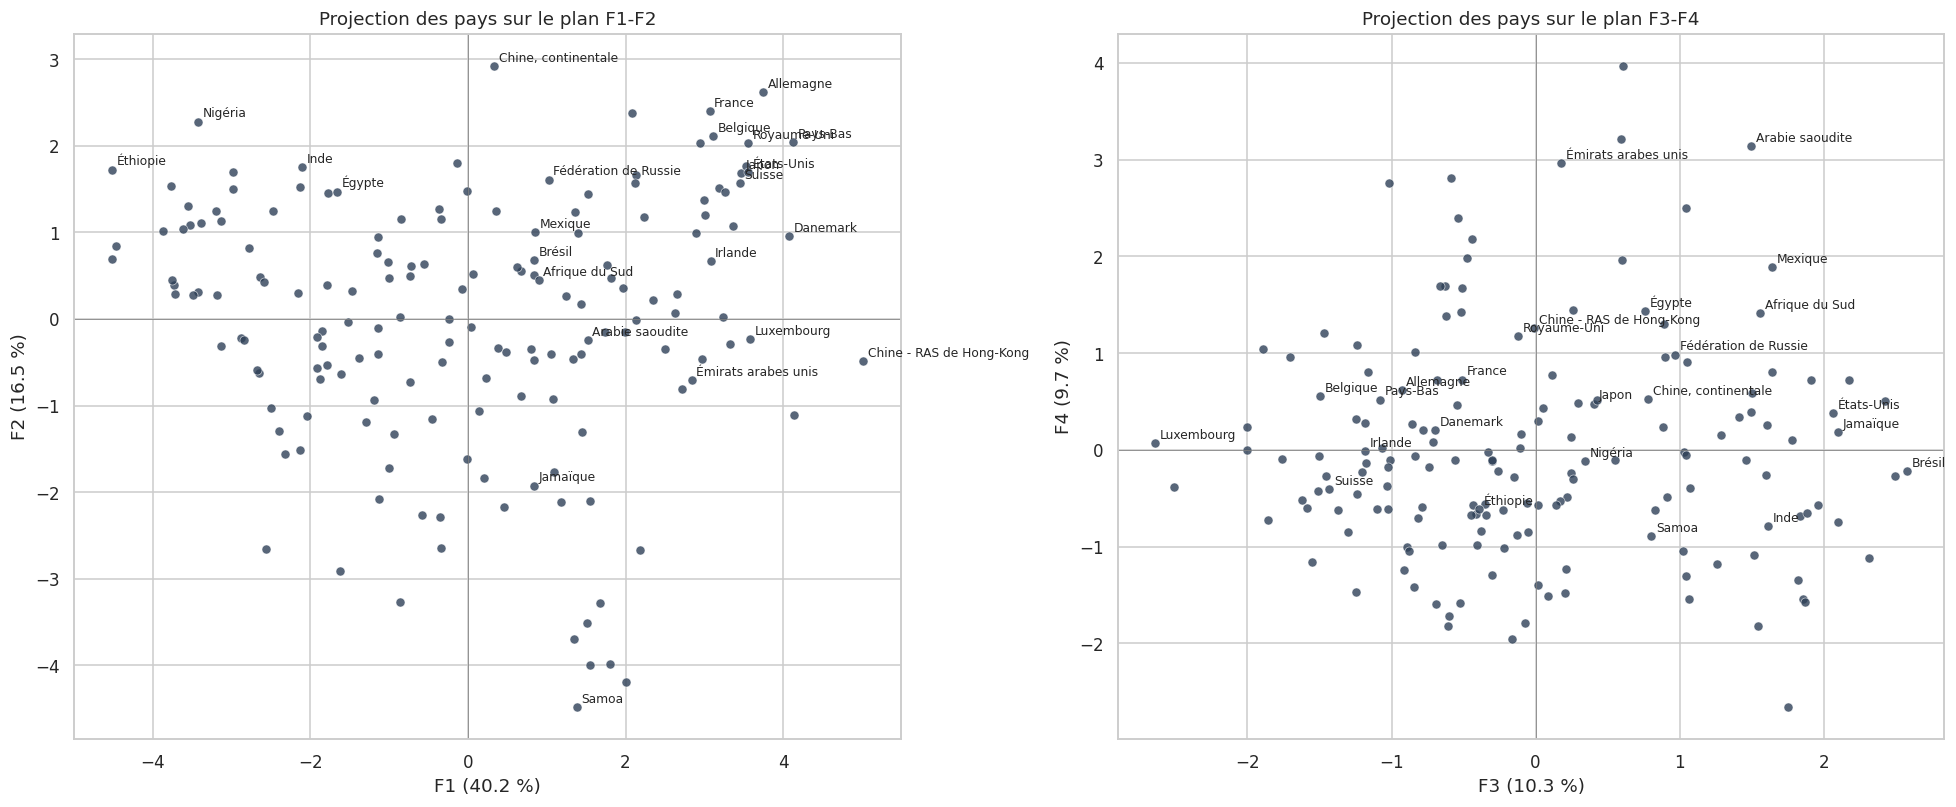

In [7]:
SHOW = ["FRA", "DEU", "GBR", "NLD", "BEL", "CHE", "USA", "CHN", "IND", "BRA", "JPN", "HKG", "ARE",
        "SAU", "NGA", "ETH", "RUS", "MEX", "ZAF", "JAM", "WSM", "EGY", "LUX", "IRL", "DNK"]

def plot_individuals(coords, x, y, ax, color=None, cmap=None, labels=SHOW, title=None):
    ix, iy = PC.index(x), PC.index(y)
    ax.scatter(coords[:, ix], coords[:, iy], c=color if color is not None else "#2E4057",
               cmap=cmap, s=35, alpha=.8, edgecolor="white", lw=.4)
    for i, iso in enumerate(df["iso3"]):
        if iso in labels:
            ax.annotate(df.loc[i, "zone"].split(" (")[0].replace("Royaume-Uni de Grande-Bretagne et d'Irlande du Nord",
                        "Royaume-Uni").replace("États-Unis d'Amérique", "États-Unis"),
                        (coords[i, ix], coords[i, iy]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.axhline(0, c="grey", lw=.5)
    ax.axvline(0, c="grey", lw=.5)
    ax.set_xlabel(f"{x} ({var_pct[x]:.1f} %)")
    ax.set_ylabel(f"{y} ({var_pct[y]:.1f} %)")
    ax.set_title(title or f"Projection des pays sur le plan {x}-{y}")

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
plot_individuals(coords, "F1", "F2", axes[0])
plot_individuals(coords, "F3", "F4", axes[1])
plt.tight_layout()
plt.show()

In [8]:
cos2 = coords ** 2 / (X ** 2).sum(axis=1, keepdims=True)
quality_f1f2 = pd.Series(cos2[:, :2].sum(1), index=names)
print("Mean representation quality on F1-F2:", round(quality_f1f2.mean(), 2))
print("Poorly represented on F1-F2 (cos² < 0.2):", quality_f1f2[quality_f1f2 < .2].sort_values().index.tolist())

Mean representation quality on F1-F2: 0.51
Poorly represented on F1-F2 (cos² < 0.2): ['Botswana', 'Jordanie', 'République de Moldova', 'Bosnie-Herzégovine', 'Mongolie', 'Pérou', 'Arménie', 'Géorgie', 'El Salvador', "Iran (République islamique d')", 'Oman', 'Brésil', 'Cuba', 'Bélarus', 'Équateur', 'Albanie', 'Afrique du Sud', 'Paraguay', 'Colombie', 'Uruguay', 'Bolivie (État plurinational de)', 'Tunisie', 'Arabie saoudite', 'Iraq', 'Monténégro', 'Mexique', 'Koweït', 'Venezuela (République bolivarienne du)', 'Macédoine du Nord', 'Thaïlande', 'Ghana', 'Argentine', 'Liban']


Les pays européens (France, Allemagne, Pays-Bas…) se regroupent à droite du plan F1-F2, les pays les moins avancés (Éthiopie, Niger…) à gauche, les grands pays émergents (Chine, Inde, Brésil) en haut. Les pays mal représentés sur F1-F2 sont correctement décrits par F3-F4 : c'est pourquoi le clustering utilisera **toutes les variables standardisées** plutôt que les seules 2 premières composantes.

## 3. Classification ascendante hiérarchique (CAH)
Méthode de **Ward** (minimise l'augmentation de l'inertie intra-classe à chaque fusion) sur les 13 variables standardisées, distance euclidienne.

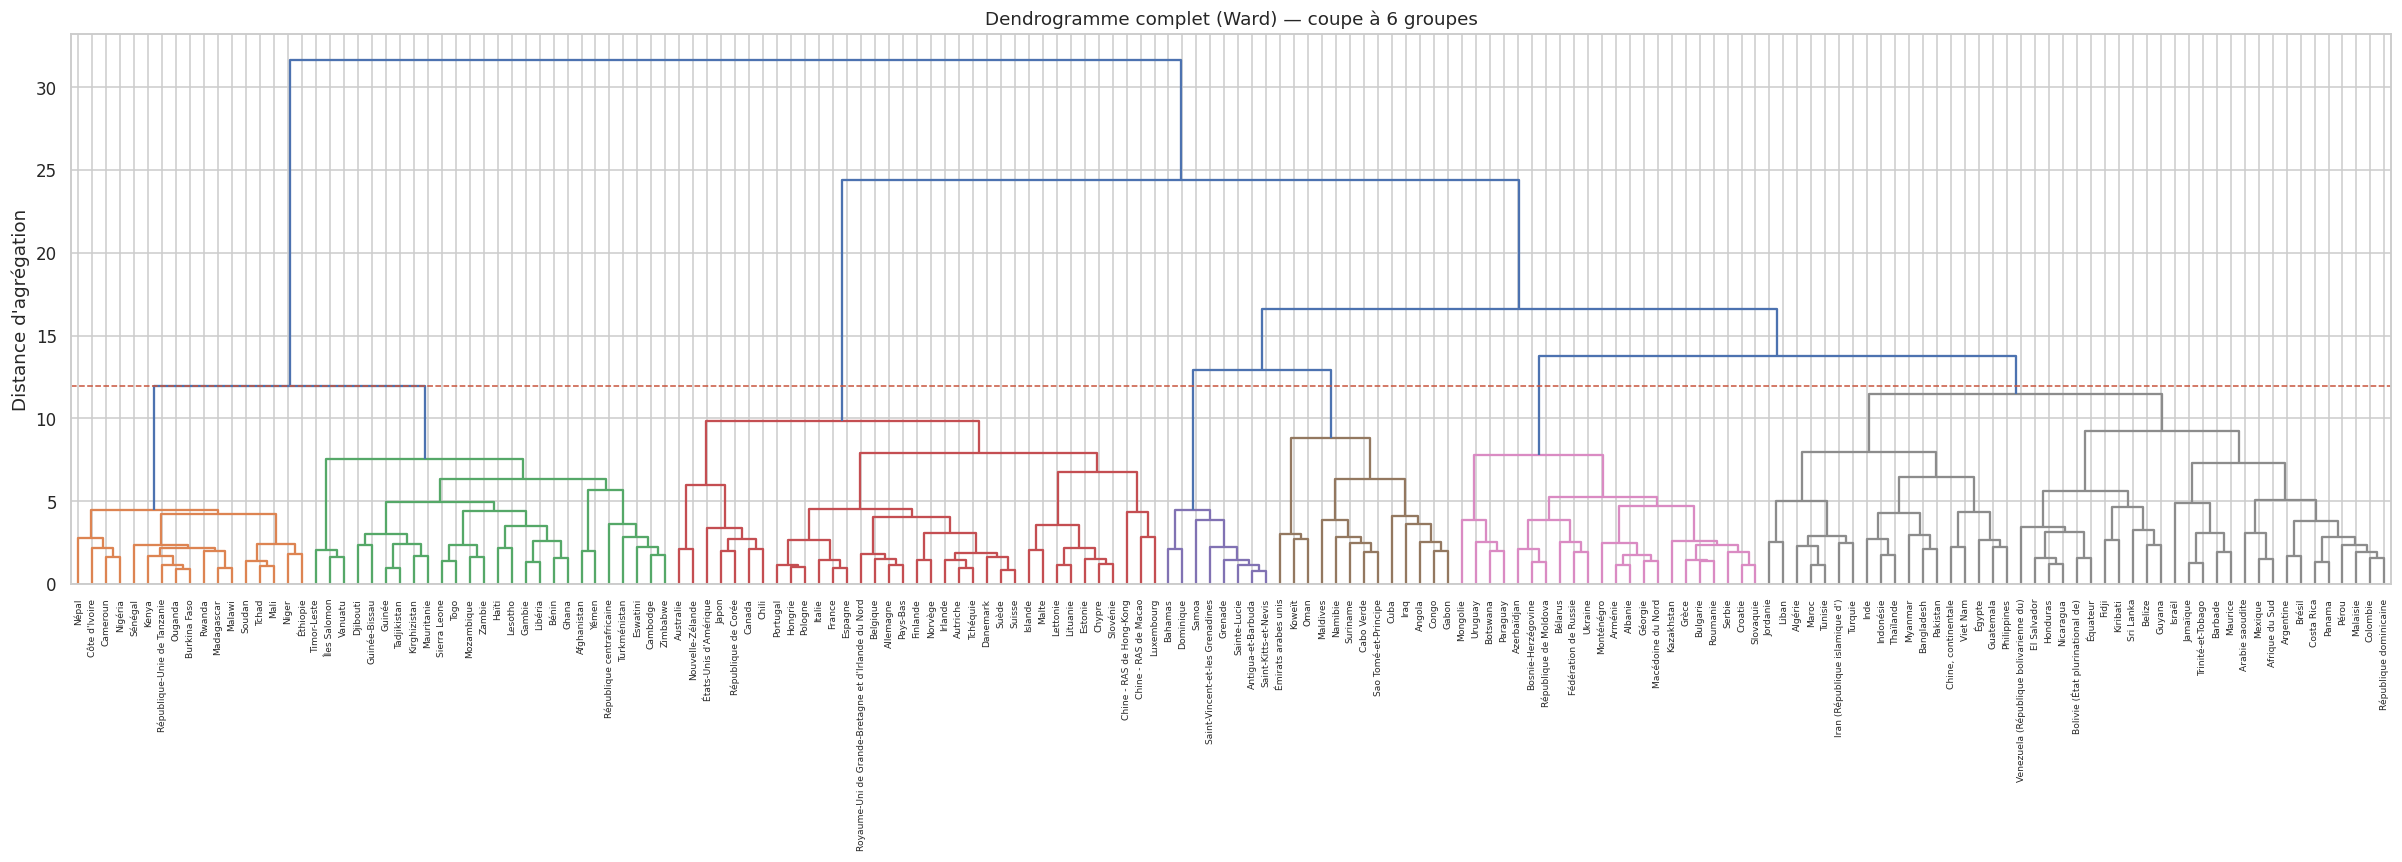

In [9]:
Z = linkage(X, method="ward", metric="euclidean")

fig, ax = plt.subplots(figsize=(22, 8))
dendrogram(Z, labels=names, leaf_rotation=90, leaf_font_size=6, color_threshold=Z[-6, 2], ax=ax)
ax.axhline(Z[-6, 2], c="#C8553D", ls="--", lw=1)
ax.set_title("Dendrogramme complet (Ward) — coupe à 6 groupes")
ax.set_ylabel("Distance d'agrégation")
plt.tight_layout()
plt.show()

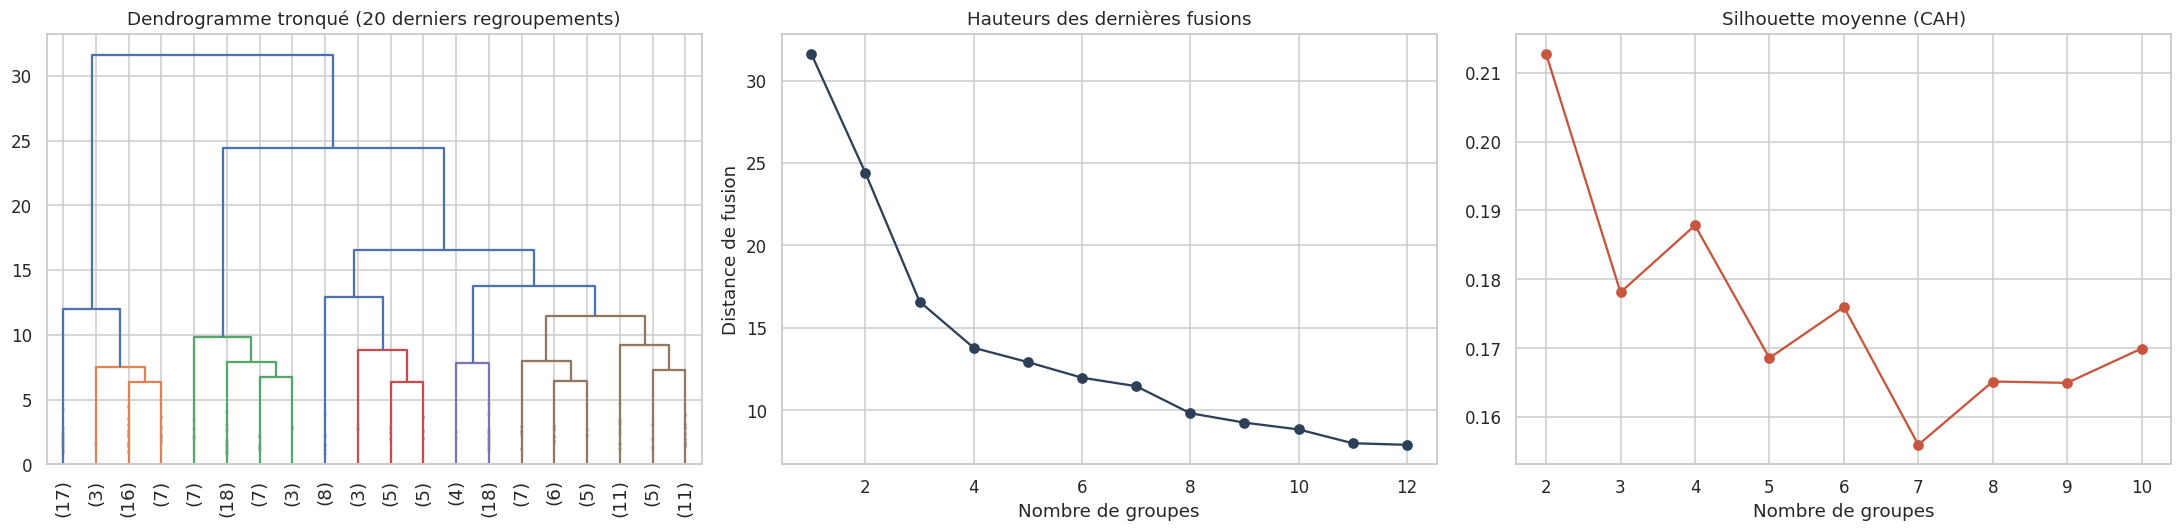

,2,3,4,5,6,7,8,9,10
silhouette_cah,0.213,0.178,0.188,0.169,0.176,0.156,0.165,0.165,0.17


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90, show_contracted=True, ax=axes[0],
           color_threshold=Z[-6, 2])
axes[0].set_title("Dendrogramme tronqué (20 derniers regroupements)")

last = Z[-12:, 2][::-1]
axes[1].plot(range(1, 13), last, "o-", c="#2E4057")
axes[1].set_xlabel("Nombre de groupes")
axes[1].set_ylabel("Distance de fusion")
axes[1].set_title("Hauteurs des dernières fusions")

sil_cah = {k: silhouette_score(X, fcluster(Z, k, "maxclust")) for k in range(2, 11)}
axes[2].plot(list(sil_cah), list(sil_cah.values()), "o-", c="#C8553D")
axes[2].set_xlabel("Nombre de groupes")
axes[2].set_title("Silhouette moyenne (CAH)")
plt.tight_layout()
plt.savefig(FIG_DIR / "cah_choice.png", dpi=200, bbox_inches="tight")
plt.show()
pd.Series(sil_cah).round(3).to_frame("silhouette_cah").T

**Choix du nombre de groupes**
- Les grands sauts de distance se situent jusqu'à 3-4 groupes ; entre 4 et 7 groupes, les hauteurs de fusion décroissent régulièrement.
- La silhouette reste faible (0,16 à 0,21), ce qui est habituel sur des données pays : les pays forment un **continuum** plutôt que des blocs parfaitement séparés.
- À 4-5 groupes, tous les pays développés (Europe, Amérique du Nord, Japon, Golfe) sont réunis dans un seul groupe — trop large pour une décision d'export.

On retient **6 groupes**, qui séparent notamment l'**Europe développée** (voisins proches) des **marchés riches et importateurs lointains**. C'est un compromis entre qualité statistique et lisibilité métier.

In [11]:
K = 6
cah_labels = fcluster(Z, K, criterion="maxclust")
df["cluster_cah"] = cah_labels
df["cluster_cah"].value_counts().sort_index().to_frame("n_countries").T

cluster_cah,1,2,3,4,5,6
n_countries,43,35,8,13,22,45


## 4. k-means
### 4.1 Choix de k

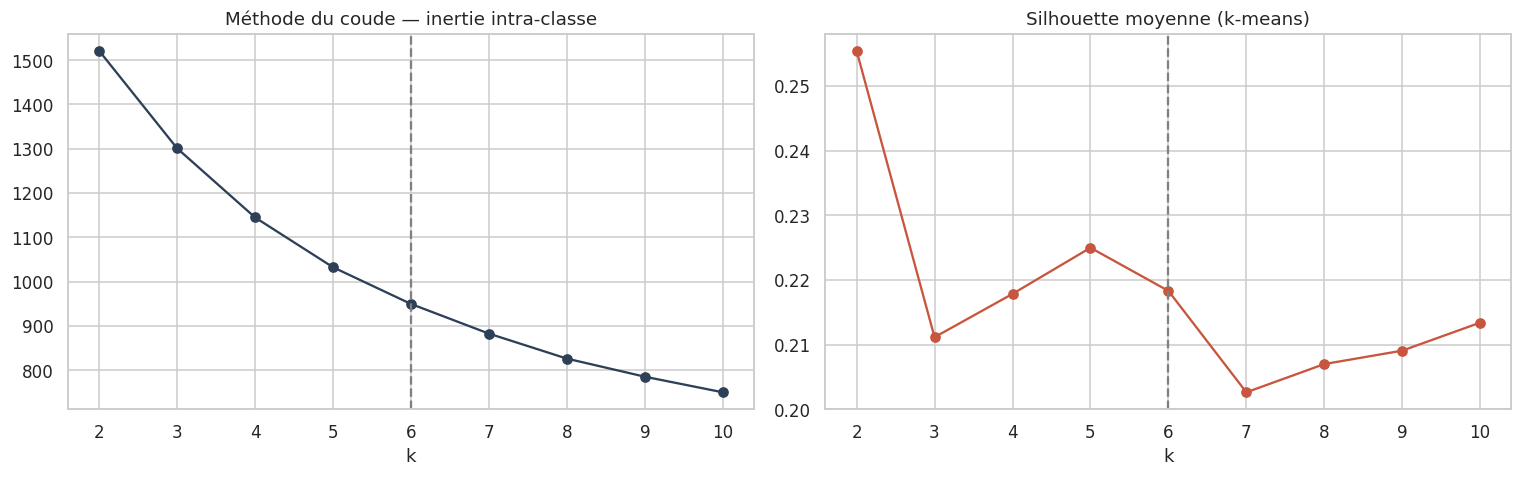

,2,3,4,5,6,7,8,9,10
inertia,1521.166,1300.898,1144.772,1032.302,949.416,882.383,825.952,785.082,749.856
silhouette,0.255,0.211,0.218,0.225,0.218,0.203,0.207,0.209,0.213


In [12]:
ks = range(2, 11)
inertia, sil_km = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=100, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    sil_km.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(ks, inertia, "o-", c="#2E4057")
axes[0].set_title("Méthode du coude — inertie intra-classe")
axes[0].set_xlabel("k")
axes[1].plot(ks, sil_km, "o-", c="#C8553D")
axes[1].set_title("Silhouette moyenne (k-means)")
axes[1].set_xlabel("k")
for ax in axes:
    ax.axvline(K, ls="--", c="grey")
plt.tight_layout()
plt.savefig(FIG_DIR / "kmeans_choice.png", dpi=200, bbox_inches="tight")
plt.show()
pd.DataFrame({"inertia": inertia, "silhouette": sil_km}, index=ks).round(3).T

Pas de coude franc (continuum) ; la silhouette est quasi identique entre k = 5 et k = 6. Par cohérence avec la CAH et pour la granularité métier, **k = 6**.

### 4.2 Modèle final et stabilité

In [13]:
kmeans = KMeans(n_clusters=K, n_init=100, random_state=RANDOM_STATE).fit(X)
km_labels = kmeans.labels_

# stability: same model with 20 other seeds
aris = [adjusted_rand_score(km_labels, KMeans(K, n_init=100, random_state=s).fit(X).labels_)
        for s in range(20)]
print(f"Silhouette k-means: {silhouette_score(X, km_labels):.3f} | "
      f"silhouette CAH: {silhouette_score(X, cah_labels):.3f}")
print(f"Stability across 20 seeds — ARI min={min(aris):.2f}, mean={np.mean(aris):.2f}")

Silhouette k-means: 0.218 | silhouette CAH: 0.176
Stability across 20 seeds — ARI min=0.94, mean=0.98


La partition k-means est **stable** (mêmes groupes quelle que soit l'initialisation) et de meilleure silhouette que la CAH.

### 4.3 Comparaison CAH / k-means

In [14]:
print("Adjusted Rand Index CAH vs k-means:", round(adjusted_rand_score(cah_labels, km_labels), 2))
pd.crosstab(pd.Series(cah_labels, name="CAH"), pd.Series(km_labels, name="k-means"))

Adjusted Rand Index CAH vs k-means: 0.43


k-means,0,1,2,3,4,5
CAH,,,,,,
1,28,0,15,0,0,0
2,0,0,0,9,0,26
3,0,8,0,0,0,0
4,0,1,9,3,0,0
5,0,0,5,0,7,10
6,2,8,0,8,27,0


Accord partiel (ARI ≈ 0,4) : les deux méthodes s'accordent sur les grandes structures (pays les moins avancés, petites îles, Europe) mais la CAH, qui ne peut pas réaffecter un pays une fois fusionné, mélange davantage les frontières. Le k-means, qui optimise directement l'inertie intra-classe, fournit une partition plus nette (silhouette supérieure) : **c'est la partition retenue**. La CAH a servi à cadrer le nombre de groupes.

## 5. Profil des groupes
Les groupes sont nommés d'après leur profil (repéré par un pays « ancre » pour rendre le nommage indépendant de la numérotation aléatoire du k-means).

In [15]:
ANCHORS = {
    "DEU": "A. Europe développée",
    "JPN": "B. Grands consommateurs hors Europe",
    "BRA": "C. Émergents autosuffisants",
    "GHA": "D. Petits marchés importateurs en développement",
    "JAM": "E. Petites îles grandes consommatrices",
    "ETH": "F. Pays à faible revenu, faible consommation",
}
anchor_cluster = {km_labels[df.index[df["iso3"] == iso][0]]: name for iso, name in ANCHORS.items()}
assert len(anchor_cluster) == K, "Two anchors fall in the same cluster"
df["cluster_km"] = km_labels
df["cluster"] = df["cluster_km"].map(anchor_cluster)
CLUSTER_ORDER = sorted(df["cluster"].unique())
PALETTE = dict(zip(CLUSTER_ORDER, ["#C8553D", "#F28F3B", "#2E4057", "#588B8B", "#93B7BE", "#8D6A9F"]))
df["cluster"].value_counts().reindex(CLUSTER_ORDER).to_frame("n_countries")

,n_countries
cluster,
A. Europe développée,36
B. Grands consommateurs hors Europe,20
C. Émergents autosuffisants,34
D. Petits marchés importateurs en développement,29
E. Petites îles grandes consommatrices,17
"F. Pays à faible revenu, faible consommation",30


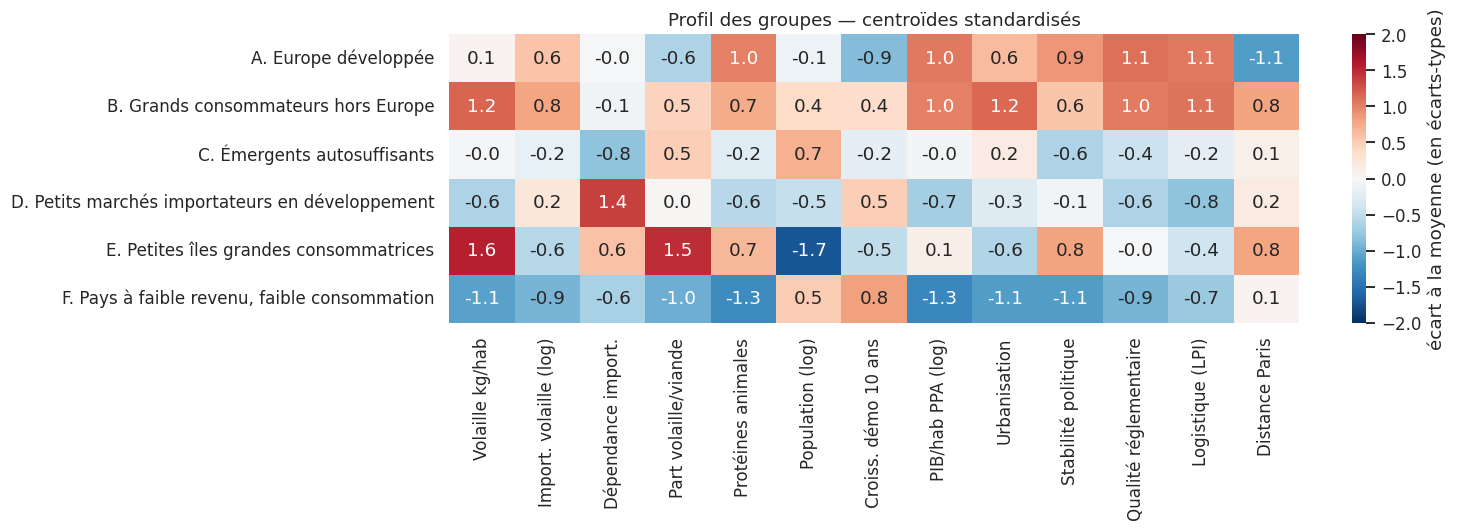

In [16]:
centroids_std = pd.DataFrame(X, columns=FEATURES).groupby(df["cluster"]).mean().reindex(CLUSTER_ORDER)
plt.figure(figsize=(14, 5))
sns.heatmap(centroids_std.rename(columns=LABELS_FR), annot=True, fmt=".1f", cmap="RdBu_r", center=0,
            vmin=-2, vmax=2, cbar_kws={"label": "écart à la moyenne (en écarts-types)"})
plt.title("Profil des groupes — centroïdes standardisés")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "cluster_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

In [17]:
PROFILE = {
    "zone": ("zone", "size"),
    "population_m": ("population", lambda s: s.sum() / 1e6),
    "imports_kt_total": ("poultry_imports_kt", "sum"),
    "imports_kt_median": ("poultry_imports_kt", "median"),
    "dependency_pct": ("import_dependency_pct", "median"),
    "kg_per_cap": ("poultry_supply_kg_cap", "median"),
    "gdp_cap_ppp": ("gdp_cap_ppp", "median"),
    "stability": ("political_stability", "median"),
    "lpi": ("lpi_score", "median"),
    "distance_km": ("distance_paris_km", "median"),
}
profile = df.groupby("cluster").agg(**PROFILE).rename(columns={"zone": "n_countries"}).reindex(CLUSTER_ORDER)
profile.round(1)

,n_countries,population_m,imports_kt_total,imports_kt_median,dependency_pct,kg_per_cap,gdp_cap_ppp,stability,lpi,distance_km
cluster,,,,,,,,,,
A. Europe développée,36,558.6,5000.0,60.5,35.2,19.9,43439.1,0.8,3.5,1354.6
B. Grands consommateurs hors Europe,20,921.5,5630.0,131.5,16.0,37.7,45989.7,0.6,3.4,8952.5
C. Émergents autosuffisants,34,4349.9,1993.0,12.5,4.0,19.8,14375.8,-0.6,2.7,8073.2
D. Petits marchés importateurs en développement,29,206.2,2037.0,29.0,87.2,9.5,5993.6,-0.2,2.5,5425.1
E. Petites îles grandes consommatrices,17,9.8,162.0,7.0,64.3,45.7,16314.2,0.8,2.7,7206.0
"F. Pays à faible revenu, faible consommation",30,1234.2,213.0,2.0,4.8,2.3,3135.6,-0.9,2.5,5577.5


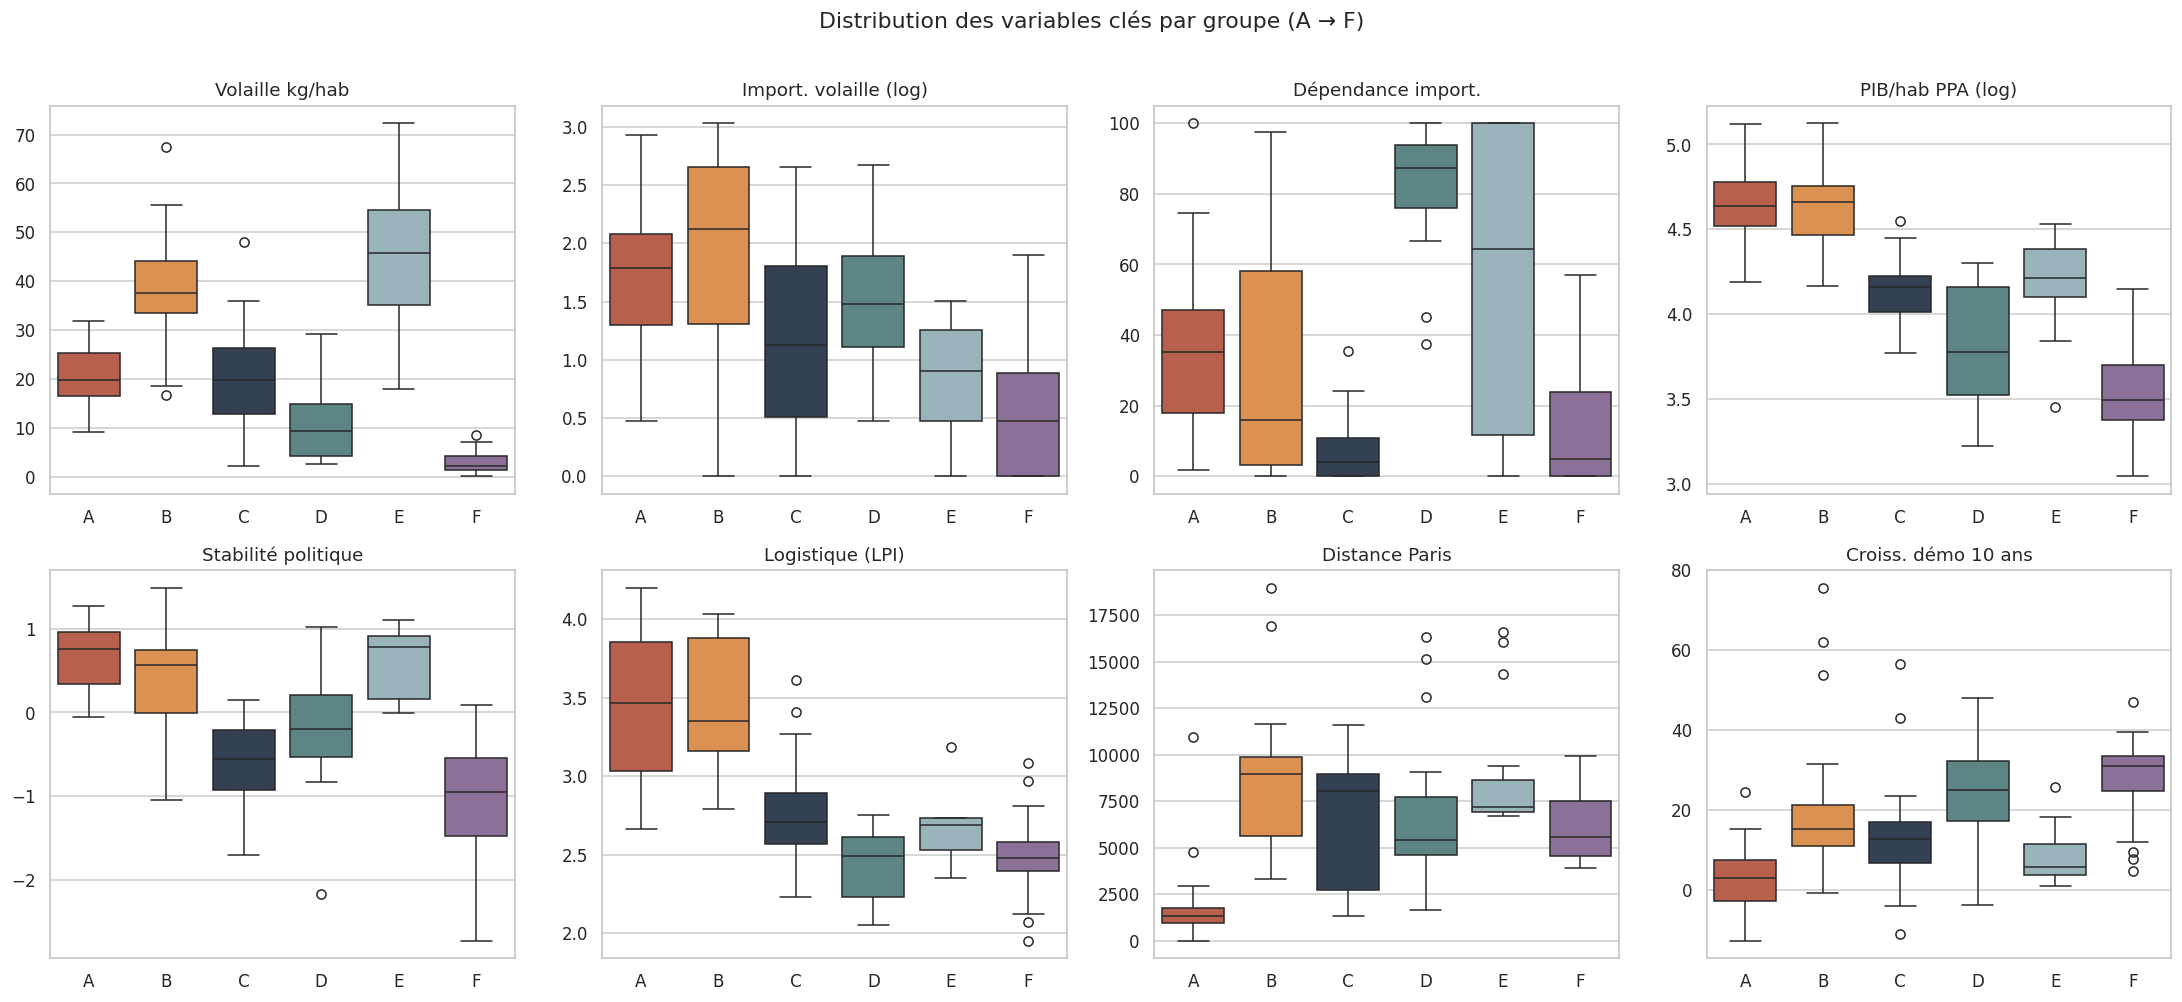

In [18]:
BOX_VARS = ["poultry_supply_kg_cap", "log_poultry_imports", "import_dependency_pct", "log_gdp_cap_ppp",
            "political_stability", "lpi_score", "distance_paris_km", "pop_growth_10y_pct"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, BOX_VARS):
    sns.boxplot(data=df, x="cluster", y=col, order=CLUSTER_ORDER, hue="cluster", palette=PALETTE,
                legend=False, ax=ax)
    ax.set_title(LABELS_FR[col])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticks(range(K))
    ax.set_xticklabels([c[0] for c in CLUSTER_ORDER])
plt.suptitle("Distribution des variables clés par groupe (A → F)", y=1.01)
plt.tight_layout()
plt.show()

In [19]:
for c in CLUSTER_ORDER:
    members = df.loc[df["cluster"] == c].sort_values("poultry_imports_kt", ascending=False)["zone"].tolist()
    print(f"\n{c} ({len(members)}) :\n  " + ", ".join(members))


A. Europe développée (36) :
  Allemagne, Royaume-Uni de Grande-Bretagne et d'Irlande du Nord, Pays-Bas, France, Belgique, Espagne, Kazakhstan, Roumanie, Danemark, Tchéquie, Autriche, Bulgarie, Irlande, Italie, Suède, Portugal, Grèce, Slovaquie, Hongrie, Pologne, Suisse, Lituanie, Lettonie, Albanie, Croatie, Estonie, Slovénie, Finlande, Chypre, Serbie, Luxembourg, Malte, Monténégro, Uruguay, Islande, Norvège

B. Grands consommateurs hors Europe (20) :
  Japon, Mexique, Chine - RAS de Hong-Kong, Arabie saoudite, Afrique du Sud, Émirats arabes unis, Canada, Chili, Koweït, République de Corée, Oman, États-Unis d'Amérique, Malaisie, Chine - RAS de Macao, Panama, Costa Rica, Australie, Argentine, Nouvelle-Zélande, Israël

C. Émergents autosuffisants (34) :
  Chine, continentale, Viet Nam, Philippines, Fédération de Russie, Guatemala, Ukraine, Égypte, Colombie, Jordanie, Pérou, République dominicaine, Azerbaïdjan, Venezuela (République bolivarienne du), Bélarus, République de Moldova, El Sal

**Lecture des groupes**
- **A. Europe développée** — riches, très stables, excellente logistique, proches (médiane ≈ 1 350 km), dépendance aux importations d'environ un tiers, gros importateurs (Allemagne, Royaume-Uni, Pays-Bas…). Contient la France. Quelques pays-frontières au profil voisin (Kazakhstan, Uruguay, Albanie).
- **B. Grands consommateurs hors Europe** — pouvoir d'achat élevé (médiane ≈ 46 000 $ PPA), forte consommation de volaille (≈ 38 kg/hab), gros volumes importés (Japon, Hong Kong, Arabie saoudite, Émirats) mais **éloignés** (médiane ≈ 9 000 km). Groupe **hétérogène** : il mêle des importateurs nets (Golfe, Hong Kong, Japon) et des producteurs autosuffisants (États-Unis, Canada, Argentine).
- **C. Émergents autosuffisants** — grands pays à revenu intermédiaire, souvent producteurs voire exportateurs (Brésil, Chine, Russie, Thaïlande) : faible dépendance aux importations, concurrence locale forte, prix bas.
- **D. Petits marchés importateurs en développement** — dépendants des importations mais petits, à faible pouvoir d'achat et logistique fragile : marché de poulet d'entrée de gamme (découpes congelées), incompatible avec un positionnement bio.
- **E. Petites îles grandes consommatrices** — très forte consommation par habitant mais populations minuscules, très éloignées.
- **F. Pays à faible revenu, faible consommation** — ~2 kg/hab/an, instabilité, pouvoir d'achat insuffisant pour un produit premium.

### 5.1 Visualisation des groupes sur les plans factoriels

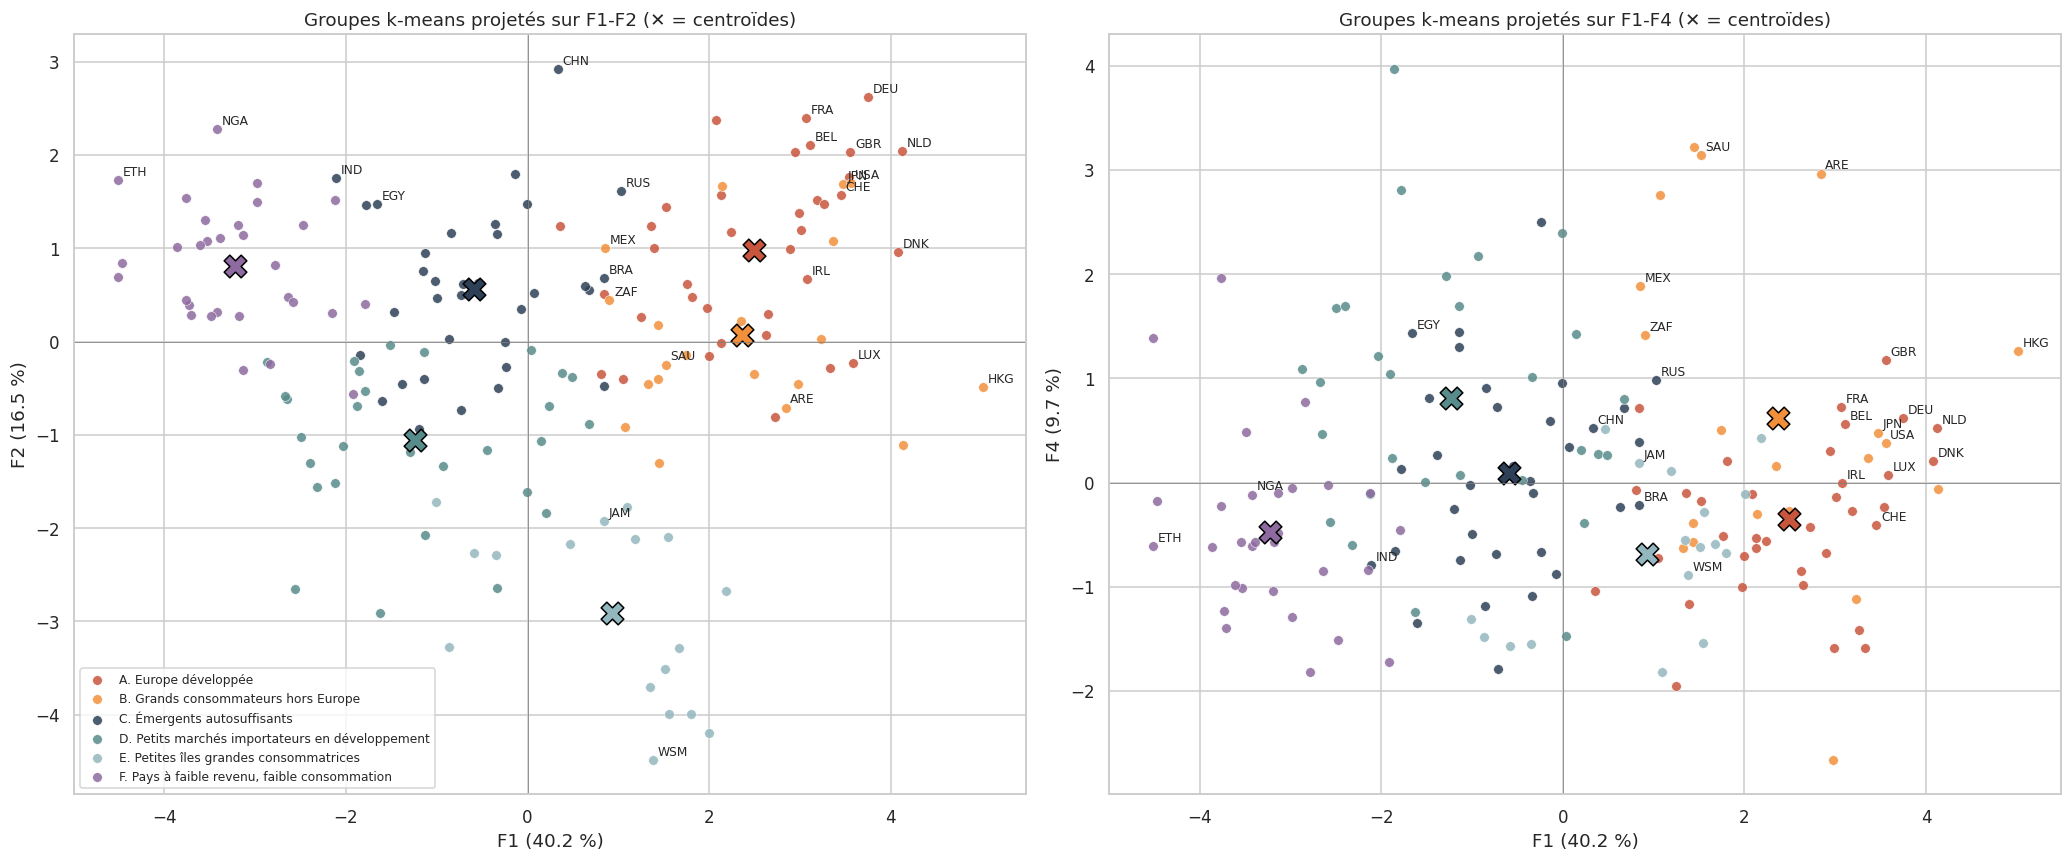

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(19, 8))
for ax, (x, y) in zip(axes, [("F1", "F2"), ("F1", "F4")]):
    ix, iy = PC.index(x), PC.index(y)
    for c in CLUSTER_ORDER:
        m = (df["cluster"] == c).to_numpy()
        ax.scatter(coords[m, ix], coords[m, iy], s=40, alpha=.85, color=PALETTE[c], label=c,
                   edgecolor="white", lw=.4)
    cent = pca.transform(kmeans.cluster_centers_)
    for k_id, name in anchor_cluster.items():
        ax.scatter(cent[k_id, ix], cent[k_id, iy], marker="X", s=220, color=PALETTE[name], edgecolor="black")
    for i, iso in enumerate(df["iso3"]):
        if iso in SHOW:
            ax.annotate(df.loc[i, "iso3"], (coords[i, ix], coords[i, iy]), fontsize=8,
                        xytext=(3, 3), textcoords="offset points")
    ax.axhline(0, c="grey", lw=.5)
    ax.axvline(0, c="grey", lw=.5)
    ax.set_xlabel(f"{x} ({var_pct[x]:.1f} %)")
    ax.set_ylabel(f"{y} ({var_pct[y]:.1f} %)")
    ax.set_title(f"Groupes k-means projetés sur {x}-{y} (✕ = centroïdes)")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "clusters_pca.png", dpi=200, bbox_inches="tight")
plt.show()

Les groupes s'étagent le long de F1 (développement) : F → D → E/C → B → A. F2 sépare les grands émergents autosuffisants (C, en haut) des petits marchés dépendants (D, E, en bas). Sur F4 (volume importé), le groupe B se détache nettement.

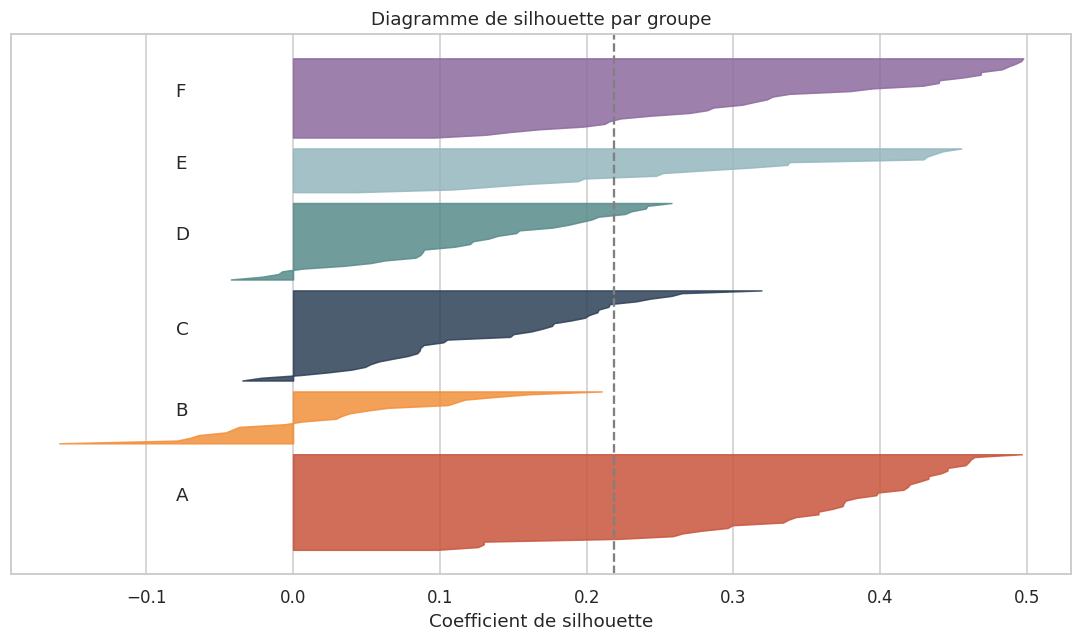

,mean,n_negative
cluster,,
A. Europe développée,0.35,0
B. Grands consommateurs hors Europe,0.03,8
C. Émergents autosuffisants,0.14,2
D. Petits marchés importateurs en développement,0.12,4
E. Petites îles grandes consommatrices,0.28,0
"F. Pays à faible revenu, faible consommation",0.33,0


In [21]:
sil_values = silhouette_samples(X, km_labels)
df["silhouette"] = sil_values
fig, ax = plt.subplots(figsize=(10, 6))
y_lower = 0
for c in CLUSTER_ORDER:
    vals = np.sort(df.loc[df["cluster"] == c, "silhouette"].to_numpy())
    ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, color=PALETTE[c], alpha=.85)
    ax.text(-0.08, y_lower + len(vals) / 2, c[0])
    y_lower += len(vals) + 3
ax.axvline(sil_values.mean(), ls="--", c="grey")
ax.set_title("Diagramme de silhouette par groupe")
ax.set_xlabel("Coefficient de silhouette")
ax.set_yticks([])
plt.tight_layout()
plt.show()
df.groupby("cluster")["silhouette"].agg(["mean", lambda s: (s < 0).sum()]).rename(
    columns={"<lambda_0>": "n_negative"}).round(2)

Les groupes A, E et F sont les plus homogènes (silhouette ≈ 0,3). Le groupe **B est peu cohésif** (silhouette ≈ 0, 8 pays négatifs) : c'est un regroupement de pays « riches hors Europe » aux profils volaille différents. Il sera donc examiné **pays par pays** et non comme un bloc.

### 5.2 Carte des groupes

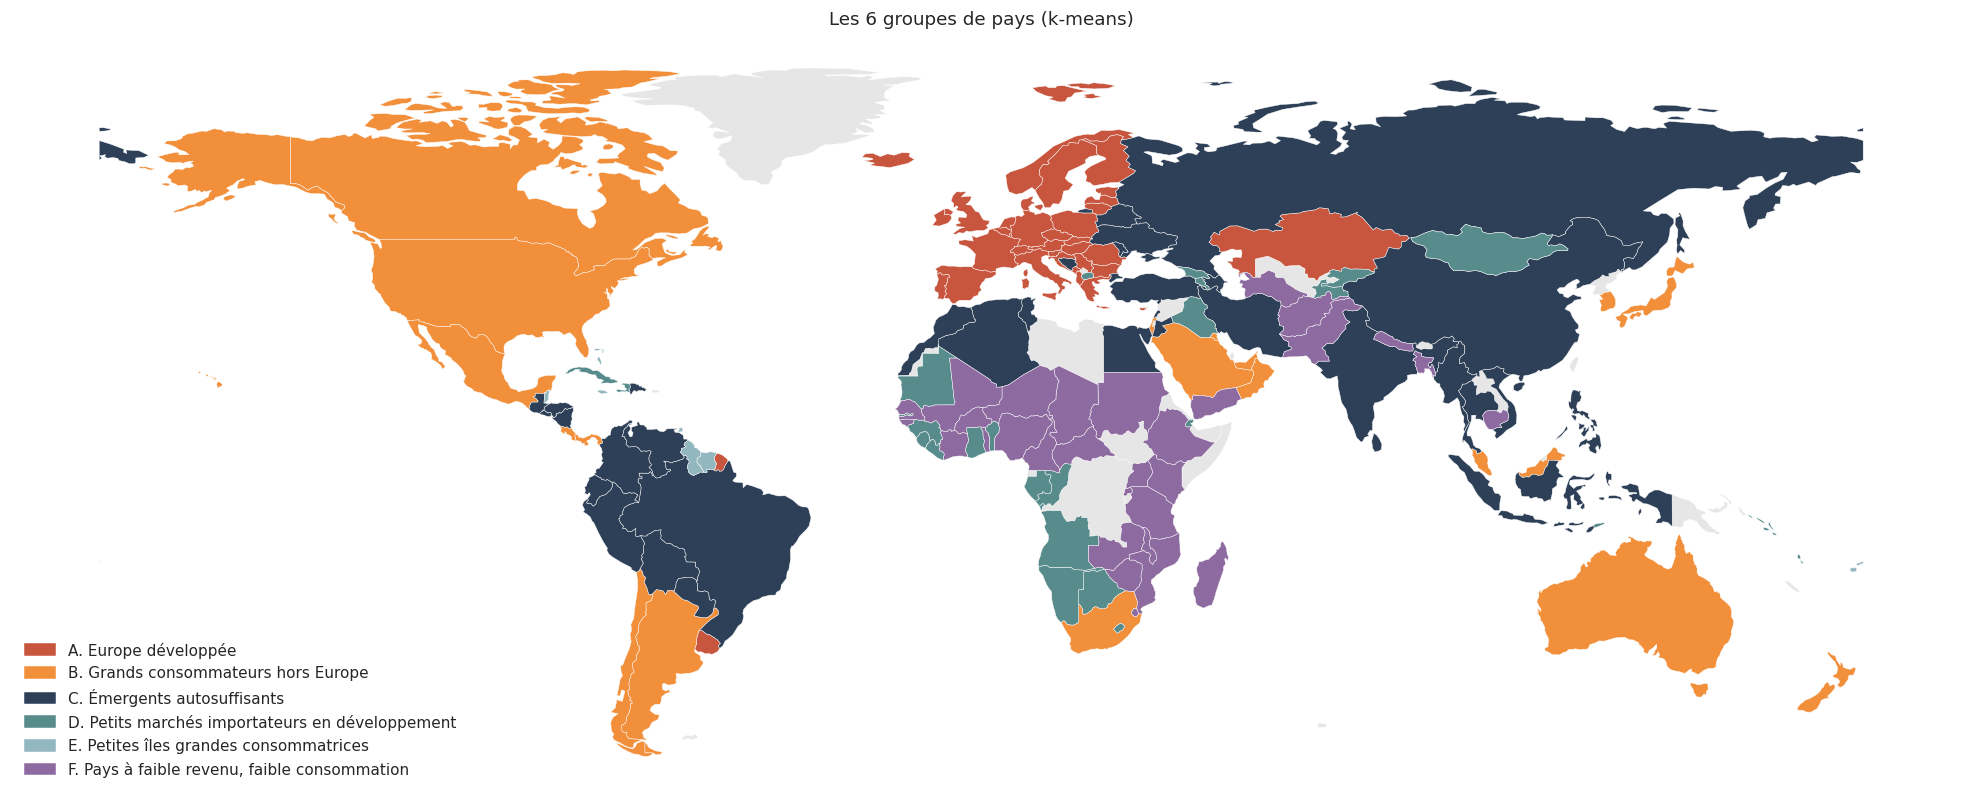

In [22]:
# Optional: requires geopandas + Natural Earth shapes (downloaded once)
try:
    import geopandas as gpd
    NE_PATH = DATA_DIR / "ne_110m_admin_0_countries.zip"
    if not NE_PATH.exists():
        import requests
        url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
        NE_PATH.write_bytes(requests.get(url, timeout=60).content)
    world = gpd.read_file(NE_PATH)[["ADM0_A3", "geometry"]]
    world = world[world["ADM0_A3"] != "ATA"]
    wmap = world.merge(df[["iso3", "cluster"]], left_on="ADM0_A3", right_on="iso3", how="left")
    fig, ax = plt.subplots(figsize=(18, 9))
    wmap[wmap["cluster"].isna()].plot(ax=ax, color="#E6E6E6", edgecolor="white", lw=.3)
    for c in CLUSTER_ORDER:
        wmap[wmap["cluster"] == c].plot(ax=ax, color=PALETTE[c], edgecolor="white", lw=.3)
    ax.legend(handles=[mpatches.Patch(color=PALETTE[c], label=c) for c in CLUSTER_ORDER],
              loc="lower left", fontsize=10, frameon=False)
    ax.set_axis_off()
    ax.set_title("Les 6 groupes de pays (k-means)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "clusters_map.png", dpi=200, bbox_inches="tight")
    plt.show()
except ImportError:
    print("geopandas not installed — map skipped")

## 6. Sélection des pays cibles
### 6.1 Choix des groupes
Critères de La poule qui chante (produit **bio, premium, frais/réfrigéré**, première expérience export) :
1. **pouvoir d'achat** suffisant pour un produit premium ;
2. **marché ouvert** : importations significatives ;
3. **risque maîtrisé** : stabilité politique, logistique fiable ;
4. **proximité** : chaîne du froid courte, coûts de transport et empreinte carbone réduits.

→ **Groupe A (Europe développée)** : cible prioritaire — il coche les 4 critères. Atout supplémentaire hors données : marché unique UE (pas de droits de douane) et **label bio européen reconnu** tel quel.
→ **Groupe B (grands consommateurs hors Europe)** : cible de **seconde phase**, pays par pays — marchés profonds mais lointains (produit congelé, certification halal dans le Golfe, normes sanitaires spécifiques au Japon).
→ Groupes C à F : écartés à ce stade (autosuffisance et concurrence prix, ou pouvoir d'achat trop faible).

### 6.2 Priorisation à l'intérieur des groupes cibles
Score d'attractivité = moyenne des variables standardisées favorables (importations, dépendance aux importations, PIB/hab, consommation/hab, stabilité, logistique) moins la distance, à **poids égaux** (hypothèse simple et transparente). Filtre de taille : **importations ≥ 100 kt**, pour écarter les micro-marchés (Luxembourg, Malte…). La France est exclue.

In [23]:
SCORE_POS = ["log_poultry_imports", "import_dependency_pct", "log_gdp_cap_ppp", "poultry_supply_kg_cap",
             "political_stability", "lpi_score"]
Xs = pd.DataFrame(X, columns=FEATURES)
df["attractiveness"] = (Xs[SCORE_POS].sum(axis=1) - Xs["distance_paris_km"]) / (len(SCORE_POS) + 1)

TARGETS = ["A. Europe développée", "B. Grands consommateurs hors Europe"]
MIN_IMPORTS_KT = 100
short = (df[df["cluster"].isin(TARGETS) & (df["poultry_imports_kt"] >= MIN_IMPORTS_KT) & (df["iso3"] != "FRA")]
         .sort_values("attractiveness", ascending=False))
short["rank_in_cluster"] = short.groupby("cluster")["attractiveness"].rank(ascending=False).astype(int)
cols = ["zone", "cluster", "rank_in_cluster", "attractiveness", "poultry_imports_kt", "import_dependency_pct",
        "poultry_supply_kg_cap", "gdp_cap_ppp", "political_stability", "lpi_score", "distance_paris_km"]
short[cols].round(2).reset_index(drop=True)

,zone,cluster,rank_in_cluster,attractiveness,poultry_imports_kt,import_dependency_pct,poultry_supply_kg_cap,gdp_cap_ppp,political_stability,lpi_score,distance_paris_km
0,Émirats arabes unis,B. Grands consommateurs hors Europe,1,1.33,433.0,90.02,43.47,72529.04,0.72,3.96,5238.97
1,Chine - RAS de Hong-Kong,B. Grands consommateurs hors Europe,2,1.32,907.0,97.42,53.51,65662.85,0.68,3.92,9615.84
2,Allemagne,A. Europe développée,1,1.15,842.0,35.74,19.47,61965.43,0.70,4.20,878.02
3,Royaume-Uni de Grande-Bretagne et d'Irlande du...,A. Europe développée,2,1.13,779.0,30.04,31.94,52429.13,0.44,3.99,342.82
4,Pays-Bas,A. Europe développée,3,1.12,608.0,35.60,20.33,65665.99,0.78,4.02,430.10
5,Danemark,A. Europe développée,4,1.11,133.0,43.46,28.98,64989.45,0.91,3.99,1026.70
6,Autriche,A. Europe développée,5,1.00,110.0,42.64,18.20,62535.81,0.93,4.03,1033.72
7,Belgique,A. Europe développée,6,0.96,338.0,42.20,12.65,58529.33,0.36,4.04,263.38
8,Tchéquie,A. Europe développée,7,0.92,116.0,41.58,21.96,45177.52,1.02,3.68,881.69
9,Canada,B. Grands consommateurs hors Europe,3,0.85,182.0,11.38,39.02,56612.31,1.02,3.73,5648.39


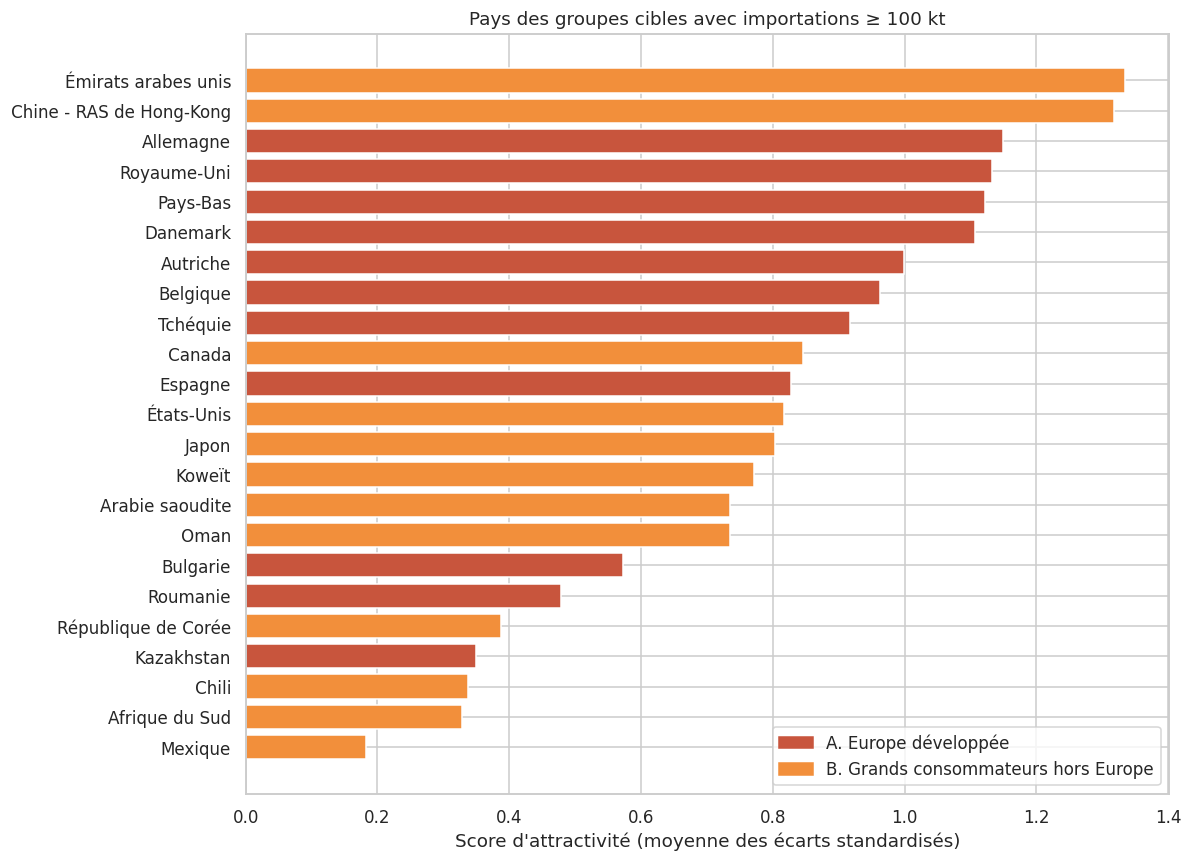

In [24]:
fig, ax = plt.subplots(figsize=(11, 8))
plot_df = short.sort_values("attractiveness")
ax.barh(plot_df["zone"].str.replace("Royaume-Uni de Grande-Bretagne et d'Irlande du Nord", "Royaume-Uni")
        .str.replace("États-Unis d'Amérique", "États-Unis"),
        plot_df["attractiveness"], color=plot_df["cluster"].map(PALETTE))
ax.legend(handles=[mpatches.Patch(color=PALETTE[c], label=c) for c in TARGETS], loc="lower right")
ax.set_xlabel("Score d'attractivité (moyenne des écarts standardisés)")
ax.set_title(f"Pays des groupes cibles avec importations ≥ {MIN_IMPORTS_KT} kt")
plt.tight_layout()
plt.savefig(FIG_DIR / "shortlist.png", dpi=200, bbox_inches="tight")
plt.show()

### 6.3 Robustesse du classement
Le score repose sur des poids égaux. On vérifie que le haut du classement du groupe A ne dépend pas de ce choix en retirant chaque critère à tour de rôle.

In [25]:
crit = SCORE_POS + ["distance_paris_km"]
signs = {c: (-1 if c == "distance_paris_km" else 1) for c in crit}
grp_a = short[short["cluster"] == TARGETS[0]].index
top_counts = pd.Series(0, index=df.loc[grp_a, "zone"])
for drop in crit:
    used = [c for c in crit if c != drop]
    s = sum(Xs.loc[grp_a, c] * signs[c] for c in used) / len(used)
    top5 = df.loc[s.sort_values(ascending=False).index[:5], "zone"]
    top_counts[top5] += 1
top_counts.sort_values(ascending=False).rename(f"times in top 5 (out of {len(crit)} variants)").to_frame()

,times in top 5 (out of 7 variants)
zone,
Allemagne,7
Royaume-Uni de Grande-Bretagne et d'Irlande du Nord,7
Pays-Bas,7
Danemark,7
Autriche,4
Belgique,2
Tchéquie,1
Espagne,0
Bulgarie,0


Les pays qui restent dans le top 5 quelle que soit la variante constituent le cœur de la recommandation.

## 7. Conclusions et recommandations

**Pays recommandés — phase 1 (groupe A, Europe développée)** — top 5 stable quelle que soit la variante du score :
- **Allemagne** : 1ᵉʳ importateur européen de volaille (≈ 840 kt), pouvoir d'achat élevé, 880 km, marché unique, premier marché bio d'Europe → **pays qui ressort le plus**.
- **Pays-Bas** : 608 kt importés, 430 km, hub logistique (Rotterdam) vers l'Europe du Nord.
- **Royaume-Uni** : 2ᵉ importateur européen (≈ 780 kt), forte consommation (≈ 32 kg/hab) ; à nuancer : depuis le Brexit (postérieur à ces données 2017), contrôles sanitaires et formalités douanières.
- **Danemark** : marché plus petit (133 kt) mais riche, ouvert (44 % importé) et très consommateur de bio.

**Second rang (groupe A)** : Autriche, Belgique (338 kt, 260 km — pertinente en test logistique grâce à la proximité, même si son score est pénalisé par une consommation par habitant modérée).

**Phase 2 (groupe B)** : Émirats arabes unis, Hong Kong, Japon, Arabie saoudite — importateurs nets solvables, mais éloignés : produit congelé, certification halal (Golfe), exigences sanitaires spécifiques. États-Unis et Canada, bien classés, sont **autosuffisants** (dépendance < 12 %) et ne sont pas prioritaires.

**Limites**
- Données de **2017** (bilans FAO) : à actualiser avant décision (dernières années FAOSTAT disponibles).
- Aucune variable ne mesure spécifiquement la **demande bio** ni les **prix** : l'étude de marché approfondie devra ajouter la taille du marché bio (FiBL/IFOAM), les prix de détail, les barrières réglementaires (normes sanitaires, quotas, droits de douane) et la concurrence (Pologne, Pays-Bas, Brésil).
- Le score d'attractivité repose sur une pondération égale ; il sert à prioriser, pas à décider.

In [26]:
out_cols = ["iso3", "zone", "wb_region", "cluster", "cluster_cah", "attractiveness", "silhouette"] + \
           [c for c in df.columns if c in FEATURES or c in ("population", "poultry_imports_kt", "gdp_cap_ppp")] + PC
df_out = pd.concat([df, pd.DataFrame(coords, columns=PC)], axis=1)
df_out[[c for c in dict.fromkeys(out_cols) if c in df_out]].to_csv(DATA_DIR / "p11_countries_clusters.csv", index=False)
print("Saved:", DATA_DIR / "p11_countries_clusters.csv")

Saved: data/p11_countries_clusters.csv
